# Student Performance Prediction
## Model Comparison Project

**Project objective:** compare six regression models for predicting students' Math, Reading, and Writing scores.

This project focuses on evaluating and comparing fixed model configurations. It does **not** include hyperparameter tuning, Grid Search, or attempts to improve individual model scores.

## 1. Import Libraries

Import the libraries required for data handling, visualization, preprocessing, model training, and evaluation.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the Dataset

Load the student performance dataset and inspect its first rows and structure.

In [ ]:
df = pd.read_csv("Expanded_data_with_more_features.csv")

display(df.head())

,Unnamed: 0,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,0,female,NaN,bachelor's degree,standard,none,married,regularly,yes,3.0,school_bus,< 5,71,71,74
1,1,female,group C,some college,standard,NaN,married,sometimes,yes,0.0,NaN,5 - 10,69,90,88
2,2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5,87,93,91
3,3,male,group A,associate's degree,free/reduced,none,married,never,no,1.0,NaN,5 - 10,45,56,42
4,4,male,group C,some college,standard,none,married,sometimes,yes,0.0,school_bus,5 - 10,76,78,75


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30641 entries, 0 to 30640
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           30641 non-null  int64  
 1   Gender               30641 non-null  str    
 2   EthnicGroup          28801 non-null  str    
 3   ParentEduc           28796 non-null  str    
 4   LunchType            30641 non-null  str    
 5   TestPrep             28811 non-null  str    
 6   ParentMaritalStatus  29451 non-null  str    
 7   PracticeSport        30010 non-null  str    
 8   IsFirstChild         29737 non-null  str    
 9   NrSiblings           29069 non-null  float64
 10  TransportMeans       27507 non-null  str    
 11  WklyStudyHours       29686 non-null  str    
 12  MathScore            30641 non-null  int64  
 13  ReadingScore         30641 non-null  int64  
 14  WritingScore         30641 non-null  int64  
dtypes: float64(1), int64(4), str(10)
memory usage: 

## 3. Data Inspection and Cleaning

Remove the unnecessary index column if it exists. Then inspect missing values, duplicate rows, and descriptive statistics.

No target values or useful input features are removed in this step.

In [5]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Dataset shape:", df.shape)

Dataset shape: (30641, 14)


In [6]:
display(df.isnull().sum().to_frame("Missing Values"))


,Missing Values
Gender,0
EthnicGroup,1840
ParentEduc,1845
LunchType,0
TestPrep,1830
ParentMaritalStatus,1190
PracticeSport,631
IsFirstChild,904
NrSiblings,1572
TransportMeans,3134


In [7]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [8]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Gender,30641,2,female,15424,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EthnicGroup,28801,5,group C,9212,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ParentEduc,28796,6,some college,6633,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LunchType,30641,2,standard,19905,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TestPrep,28811,2,none,18856,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ParentMaritalStatus,29451,4,married,16844,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PracticeSport,30010,3,sometimes,15213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IsFirstChild,29737,2,yes,19082,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NrSiblings,29069.0,NaN,NaN,NaN,2.145894,1.458242,0.0,1.0,2.0,3.0,7.0
TransportMeans,27507,2,school_bus,16145,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Exploratory Data Analysis (EDA)

The following plots provide a brief overview of the three target variables and selected feature relationships. This section is descriptive; it does not modify the data or tune the models.

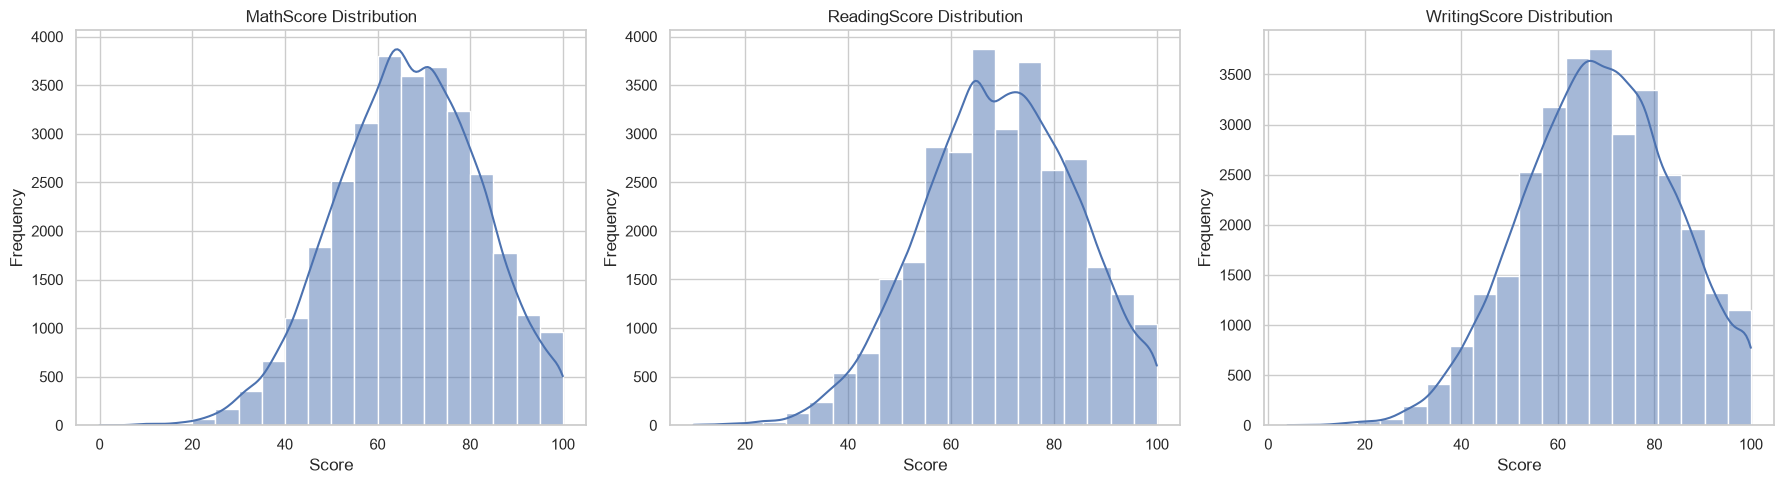

In [9]:
targets = ["MathScore", "ReadingScore", "WritingScore"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, target in zip(axes, targets):
    sns.histplot(data=df, x=target, kde=True, bins=20, ax=ax)
    ax.set_title(f"{target} Distribution")
    ax.set_xlabel("Score")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

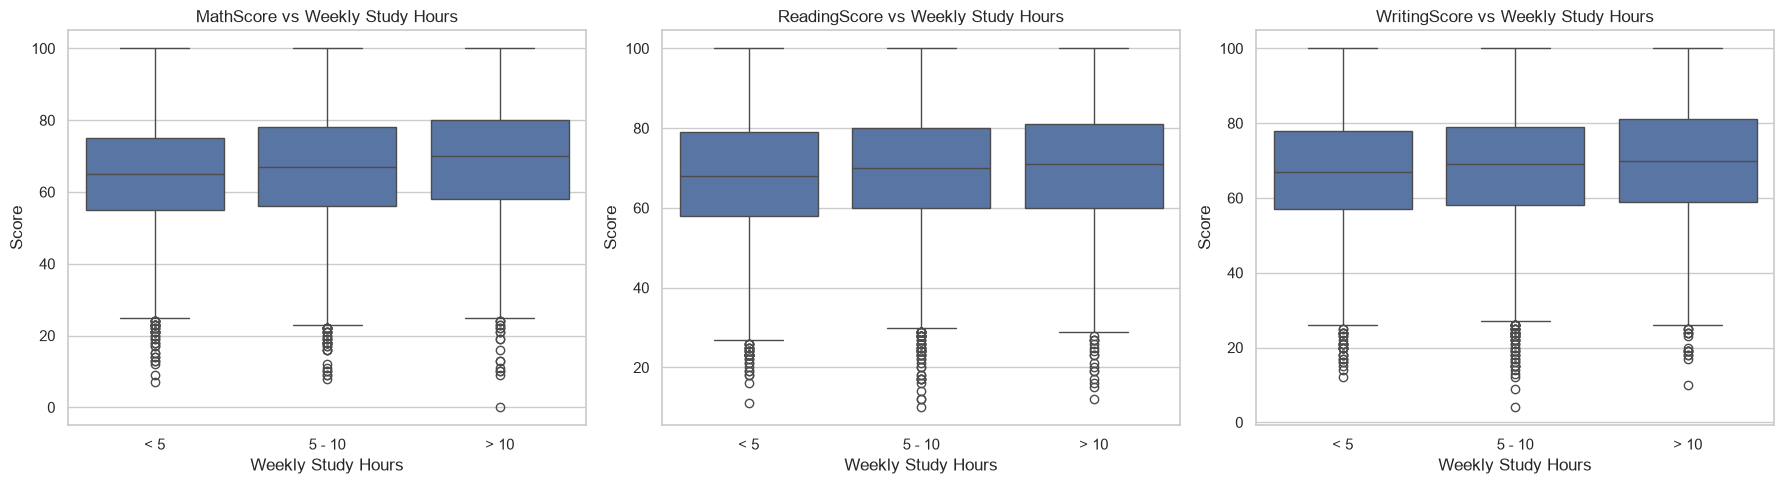

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, target in zip(axes, targets):
    sns.boxplot(data=df, x="WklyStudyHours", y=target, ax=ax)
    ax.set_title(f"{target} vs Weekly Study Hours")
    ax.set_xlabel("Weekly Study Hours")
    ax.set_ylabel("Score")

plt.tight_layout()
plt.show()

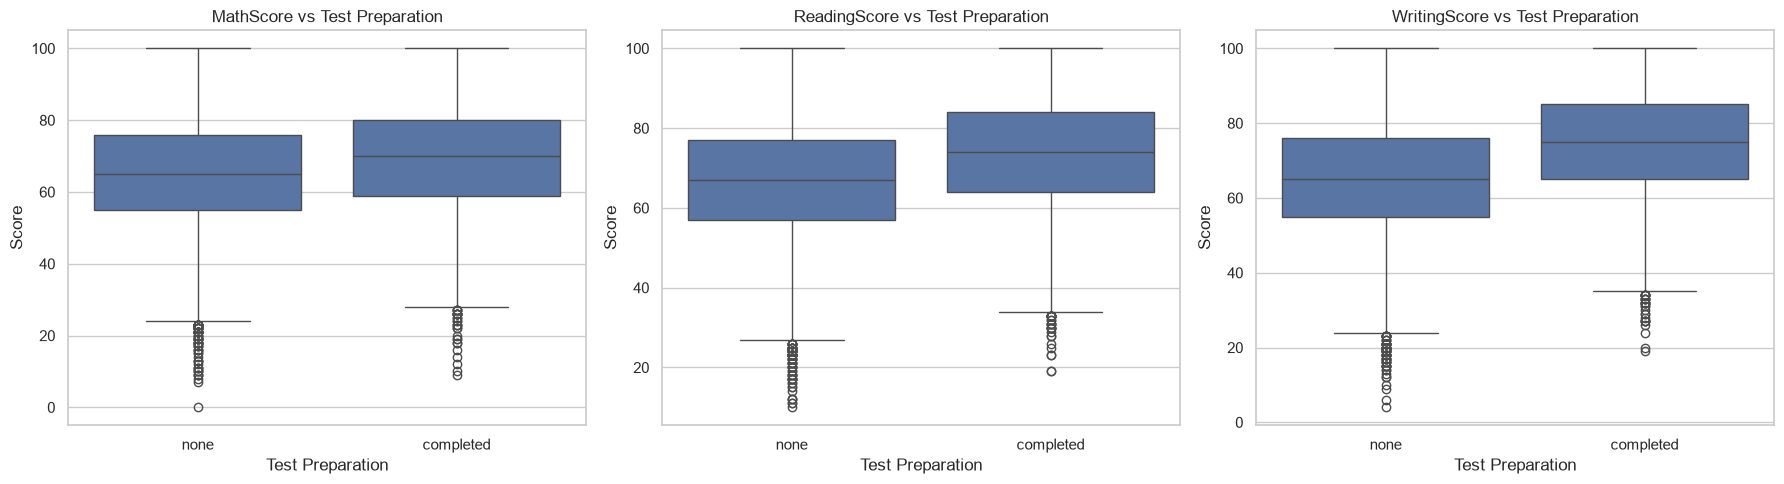

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, target in zip(axes, targets):
    sns.boxplot(data=df, x="TestPrep", y=target, ax=ax)
    ax.set_title(f"{target} vs Test Preparation")
    ax.set_xlabel("Test Preparation")
    ax.set_ylabel("Score")

plt.tight_layout()
plt.show()

In [12]:
testprep_analysis = df.groupby("TestPrep")[targets].agg(["count", "mean", "median"])
display(testprep_analysis.round(2))

MathScore               ReadingScore               WritingScore  \
              count   mean median        count   mean median        count   
TestPrep                                                                    
completed      9955  69.55   70.0         9955  73.73   74.0         9955   
none          18856  64.95   65.0        18856  67.05   67.0        18856   

                         
            mean median  
TestPrep                 
completed  74.70   75.0  
none       65.09   65.0

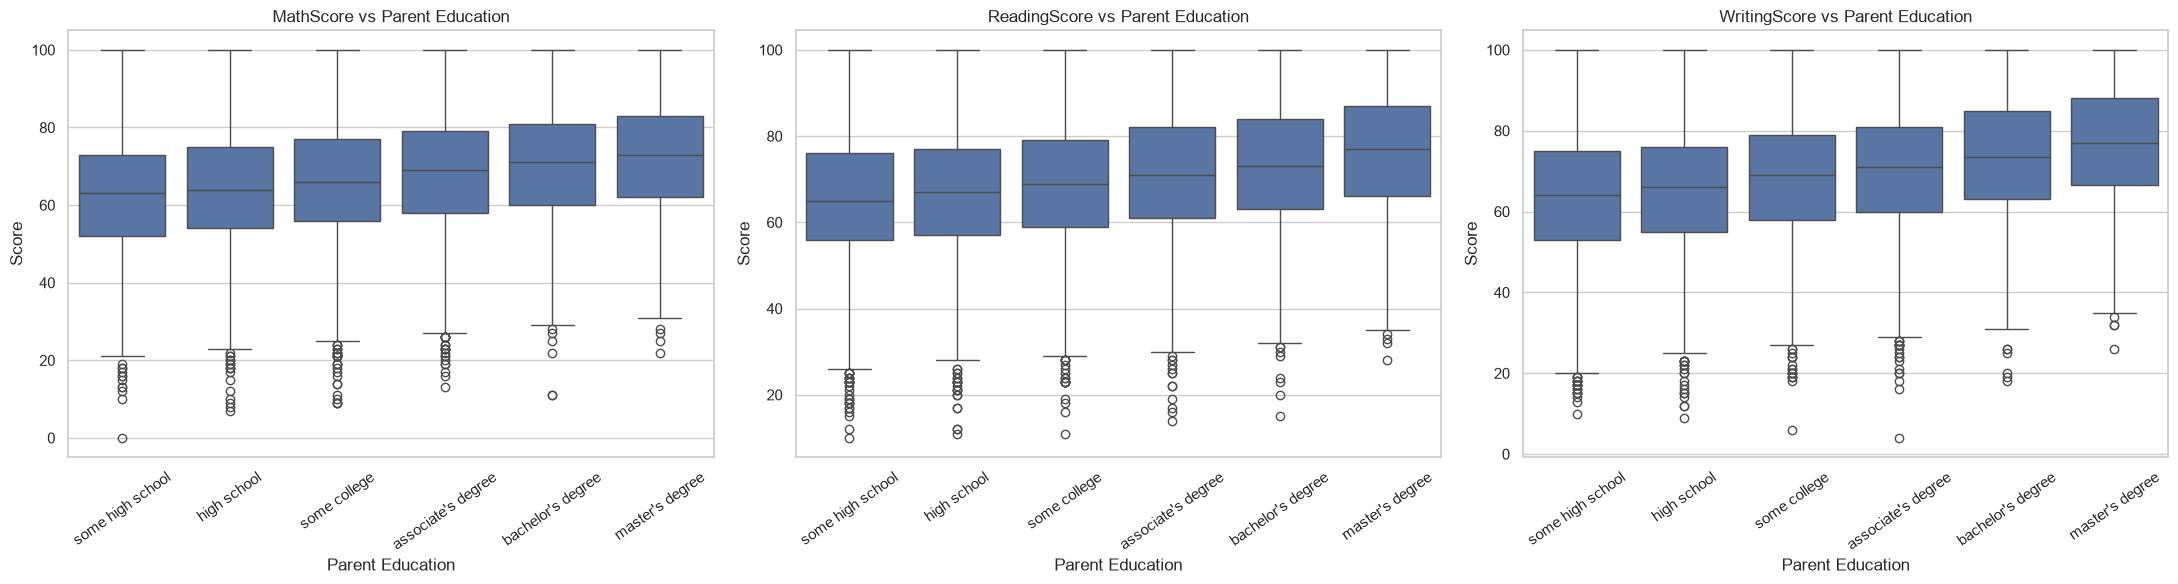

In [13]:
education_order = [
    "some high school",
    "high school",
    "some college",
    "associate's degree",
    "bachelor's degree",
    "master's degree"
]

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

for ax, target in zip(axes, targets):
    sns.boxplot(
        data=df,
        x="ParentEduc",
        y=target,
        order=education_order,
        ax=ax
    )
    ax.set_title(f"{target} vs Parent Education")
    ax.set_xlabel("Parent Education")
    ax.set_ylabel("Score")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

In [14]:
parent_education_analysis = df.groupby("ParentEduc")[targets].agg(
    ["count", "mean", "median"]
)
display(parent_education_analysis.round(2))

MathScore               ReadingScore                \
                       count   mean median        count   mean median   
ParentEduc                                                              
associate's degree      5550  68.37   69.0         5550  71.12   71.0   
bachelor's degree       3386  70.47   71.0         3386  73.06   73.0   
high school             5687  64.44   64.0         5687  67.21   67.0   
master's degree         2023  72.34   73.0         2023  75.83   77.0   
some college            6633  66.39   66.0         6633  69.18   69.0   
some high school        5517  62.58   63.0         5517  65.51   65.0   

                   WritingScore                
                          count   mean median  
ParentEduc                                     
associate's degree         5550  70.30   71.0  
bachelor's degree          3386  73.33   73.5  
high school                5687  65.42   66.0  
master's degree            2023  76.36   77.0  
some college               6633  68.50   69.0  
some high school           5517  63.63   64.0

## 5. Define Features and Target Variables

- **X:** student-related input features.
- **y_math:** MathScore.
- **y_reading:** ReadingScore.
- **y_writing:** WritingScore.

The three target variables are predicted separately using the same input features.

In [15]:
X = df.drop(columns=targets)

y_math = df["MathScore"]
y_reading = df["ReadingScore"]
y_writing = df["WritingScore"]

print("Features shape:", X.shape)
print("Math target shape:", y_math.shape)
print("Reading target shape:", y_reading.shape)
print("Writing target shape:", y_writing.shape)

display(X.head())

Features shape: (30641, 11)
Math target shape: (30641,)
Reading target shape: (30641,)
Writing target shape: (30641,)


,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours
0,female,NaN,bachelor's degree,standard,none,married,regularly,yes,3.0,school_bus,< 5
1,female,group C,some college,standard,NaN,married,sometimes,yes,0.0,NaN,5 - 10
2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5
3,male,group A,associate's degree,free/reduced,none,married,never,no,1.0,NaN,5 - 10
4,male,group C,some college,standard,none,married,sometimes,yes,0.0,school_bus,5 - 10


In [16]:
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
numerical_features = X.select_dtypes(include=np.number).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)
print("Number of categorical features:", len(categorical_features))
print("Number of numerical features:", len(numerical_features))

Categorical features: ['Gender', 'EthnicGroup', 'ParentEduc', 'LunchType', 'TestPrep', 'ParentMaritalStatus', 'PracticeSport', 'IsFirstChild', 'TransportMeans', 'WklyStudyHours']
Numerical features: ['NrSiblings']
Number of categorical features: 10
Number of numerical features: 1


## 6. Train-Test Split

Split the input data **once**. The same training and testing rows are then used for all three targets, making the comparisons consistent.

- 80% training data
- 20% testing data
- `random_state=42` for reproducibility

In [17]:
X_train, X_test, y_math_train, y_math_test, y_reading_train, y_reading_test, y_writing_train, y_writing_test = train_test_split(
    X,
    y_math,
    y_reading,
    y_writing,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Math target:", y_math_train.shape, y_math_test.shape)
print("Reading target:", y_reading_train.shape, y_reading_test.shape)
print("Writing target:", y_writing_train.shape, y_writing_test.shape)

Training features: (24512, 11)
Testing features: (6129, 11)
Math target: (24512,) (6129,)
Reading target: (24512,) (6129,)
Writing target: (24512,) (6129,)


## 7. Preprocessing

Numerical features:
- Fill missing values using the median.
- Apply StandardScaler only for Ridge and Lasso, because these regularized linear models are sensitive to feature scales.

Categorical features:
- Fill missing values using the constant value `Missing`.
- Apply One-Hot Encoding.
- Ignore unseen categories during transformation.

All preprocessing is placed inside each model pipeline. Therefore, preprocessing is fitted only on the training portion of each evaluation split, avoiding data leakage.

In [18]:
def create_preprocessor(scale_numeric=False):
    numerical_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numerical_steps.append(("scaler", StandardScaler()))

    numerical_transformer = Pipeline(steps=numerical_steps)

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(
        transformers=[
            ("num", numerical_transformer, numerical_features),
            ("cat", categorical_transformer, categorical_features)
        ]
    )

## 8. Define the Models

The project compares the following six models using fixed configurations. These settings are kept unchanged throughout the comparison.

Ridge and Lasso use scaled numerical features. The other models use the unscaled numerical features after imputation.

In [19]:
def get_models():
    return {
        "Dummy Regressor": DummyRegressor(strategy="mean"),
        "Linear Regression": LinearRegression(),
        "Ridge Regression": Ridge(alpha=1.0),
        "Lasso Regression": Lasso(alpha=1.0, max_iter=10000),
        "Random Forest": RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ),
        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        )
    }


scaled_models = ["Ridge Regression", "Lasso Regression"]

## 9. Model Evaluation on the Test Set

Each model is trained on the training set and evaluated on the same unseen test set.

Evaluation metrics:
- **MAE:** average absolute prediction error. Lower is better.
- **RMSE:** gives larger errors more weight. Lower is better.
- **R² Score:** proportion of target variance explained by the model. Higher is better.

The test set is used only for evaluation, not for model fitting or parameter selection.

In [20]:
def evaluate_models(target_name, y_train, y_test):
    results = []

    for model_name, model in get_models().items():
        scale_numeric = model_name in scaled_models

        pipeline = Pipeline(steps=[
            ("preprocessor", create_preprocessor(scale_numeric=scale_numeric)),
            ("model", model)
        ])

        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        results.append({
            "Target": target_name,
            "Model": model_name,
            "MAE": mean_absolute_error(y_test, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
            "R2 Score": r2_score(y_test, y_pred)
        })

    return pd.DataFrame(results)

In [27]:
math_results = evaluate_models("MathScore", y_math_train, y_math_test)
reading_results = evaluate_models("ReadingScore", y_reading_train, y_reading_test)
writing_results = evaluate_models("WritingScore", y_writing_train, y_writing_test)

test_results = pd.concat(
    [math_results, reading_results, writing_results],
    ignore_index=True
)

In [28]:
math_results_df = test_results[
    test_results["Target"] == "MathScore"
].drop(columns=["Target"]).reset_index(drop=True)

reading_results_df = test_results[
    test_results["Target"] == "ReadingScore"
].drop(columns=["Target"]).reset_index(drop=True)

writing_results_df = test_results[
    test_results["Target"] == "WritingScore"
].drop(columns=["Target"]).reset_index(drop=True)

In [29]:
display(math_results_df)


,Model,MAE,RMSE,R2 Score
0,Dummy Regressor,12.318216,15.237183,-0.000611
1,Linear Regression,10.374477,12.828385,0.290749
2,Ridge Regression,10.374479,12.828365,0.290751
3,Lasso Regression,11.389053,14.099940,0.143178
4,Random Forest,11.335838,14.068552,0.146989
5,Gradient Boosting,10.401805,12.868017,0.286360


In [30]:
display(reading_results_df)


,Model,MAE,RMSE,R2 Score
0,Dummy Regressor,11.869267,14.670053,-0.000273
1,Linear Regression,10.396052,12.832592,0.234608
2,Ridge Regression,10.396068,12.832599,0.234607
3,Lasso Regression,11.241801,13.854945,0.107795
4,Random Forest,11.319863,14.016066,0.086923
5,Gradient Boosting,10.412781,12.854472,0.231996


In [31]:

display(writing_results_df)

,Model,MAE,RMSE,R2 Score
0,Dummy Regressor,12.423884,15.372490,-0.000513
1,Linear Regression,10.141981,12.520337,0.336308
2,Ridge Regression,10.142026,12.520363,0.336305
3,Lasso Regression,11.175206,13.831013,0.190079
4,Random Forest,11.162812,13.815878,0.191851
5,Gradient Boosting,10.164830,12.538869,0.334342


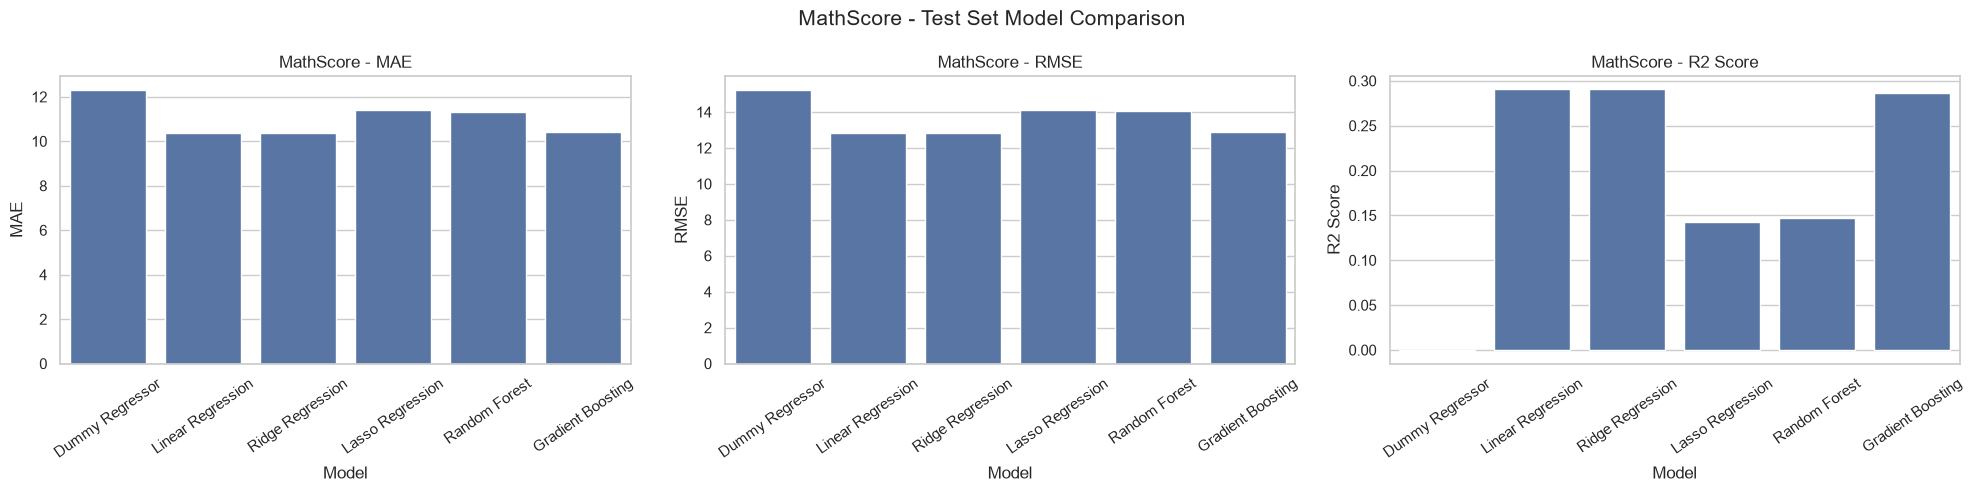

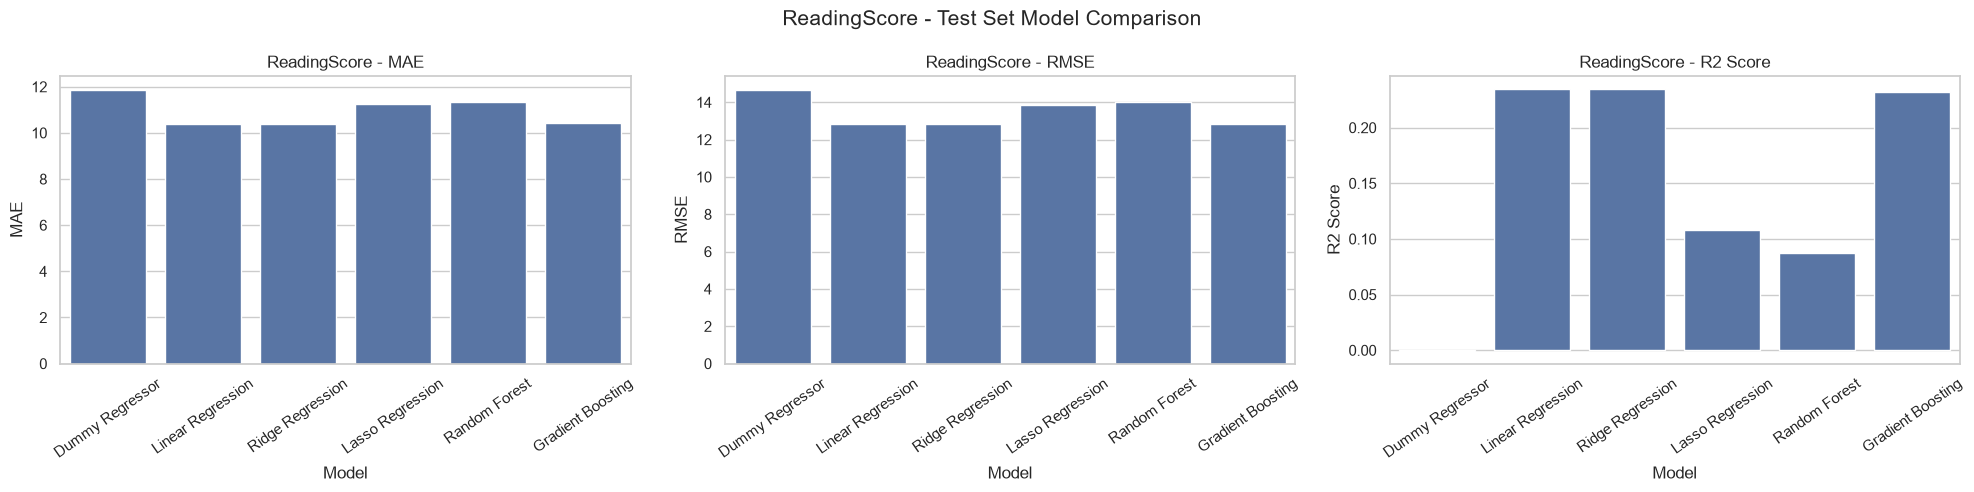

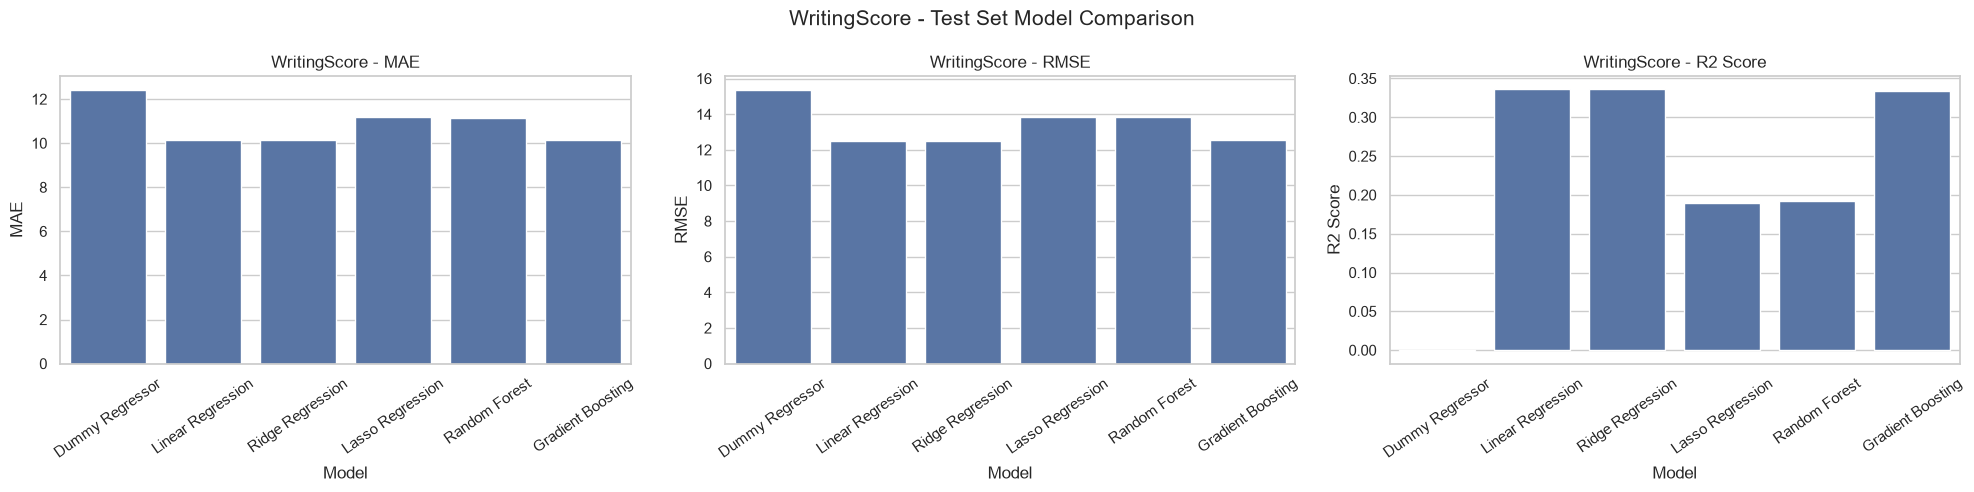

In [32]:
for target_name in targets:
    target_results = test_results[test_results["Target"] == target_name]

    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    for ax, metric in zip(axes, ["MAE", "RMSE", "R2 Score"]):
        sns.barplot(data=target_results, x="Model", y=metric, ax=ax)
        ax.set_title(f"{target_name} - {metric}")
        ax.set_xlabel("Model")
        ax.set_ylabel(metric)
        ax.tick_params(axis="x", rotation=35)

    plt.suptitle(f"{target_name} - Test Set Model Comparison", fontsize=15)
    plt.tight_layout()
    plt.show()

## 10. Five-Fold Cross-Validation

Cross-validation provides an additional comparison of model performance across five training folds. It is used to assess consistency, **not** to search for better hyperparameters.

The held-out test set remains separate from this process. Preprocessing is fitted independently inside each fold through the pipeline.

In [33]:
def cross_validate_models(target_name, y_train):
    kfold = KFold(n_splits=5, shuffle=True, random_state=42)
    results = []

    for model_name, model in get_models().items():
        scale_numeric = model_name in scaled_models

        pipeline = Pipeline(steps=[
            ("preprocessor", create_preprocessor(scale_numeric=scale_numeric)),
            ("model", model)
        ])

        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=kfold,
            scoring={
                "MAE": "neg_mean_absolute_error",
                "RMSE": "neg_root_mean_squared_error",
                "R2": "r2"
            },
            n_jobs=-1
        )

        results.append({
            "Target": target_name,
            "Model": model_name,
            "MAE Mean": -scores["test_MAE"].mean(),
            "MAE Std": scores["test_MAE"].std(),
            "RMSE Mean": -scores["test_RMSE"].mean(),
            "RMSE Std": scores["test_RMSE"].std(),
            "R2 Mean": scores["test_R2"].mean(),
            "R2 Std": scores["test_R2"].std()
        })

    return pd.DataFrame(results)

In [34]:
math_cv_results = cross_validate_models("MathScore", y_math_train)
reading_cv_results = cross_validate_models("ReadingScore", y_reading_train)
writing_cv_results = cross_validate_models("WritingScore", y_writing_train)

cv_results = pd.concat(
    [math_cv_results, reading_cv_results, writing_cv_results],
    ignore_index=True
)

display(cv_results.round(4))

,Target,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,MathScore,Dummy Regressor,12.4506,0.1199,15.3923,0.1550,-0.0002,0.0003
1,MathScore,Linear Regression,10.4942,0.1133,12.9710,0.1449,0.2896,0.0115
2,MathScore,Ridge Regression,10.4942,0.1133,12.9711,0.1449,0.2896,0.0115
3,MathScore,Lasso Regression,11.5680,0.1067,14.2819,0.1450,0.1389,0.0018
4,MathScore,Random Forest,11.4180,0.1173,14.1589,0.1577,0.1536,0.0134
5,MathScore,Gradient Boosting,10.5296,0.1140,13.0101,0.1440,0.2854,0.0110
6,ReadingScore,Dummy Regressor,12.0211,0.1076,14.7818,0.0913,-0.0004,0.0004
7,ReadingScore,Linear Regression,10.5298,0.1077,12.9771,0.0999,0.2289,0.0051
8,ReadingScore,Ridge Regression,10.5298,0.1077,12.9771,0.0999,0.2289,0.0051
9,ReadingScore,Lasso Regression,11.3839,0.0963,13.9975,0.0855,0.1029,0.0010


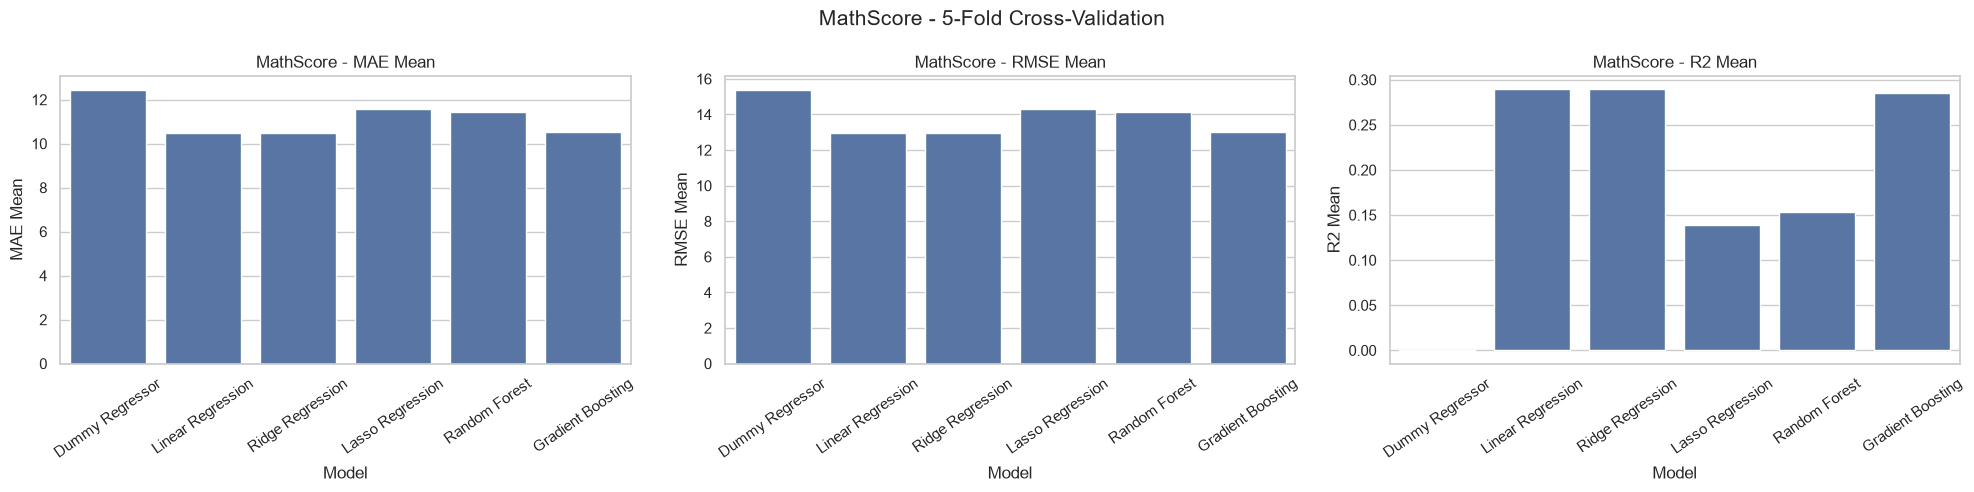

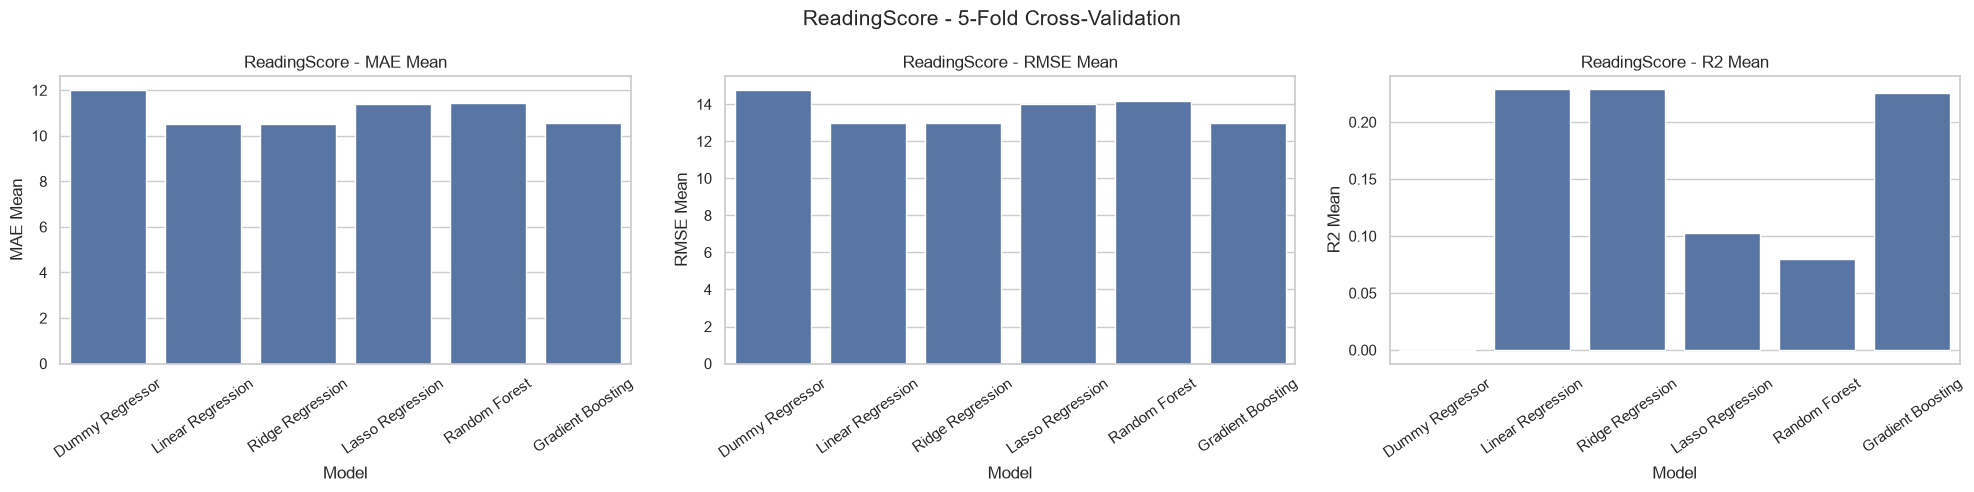

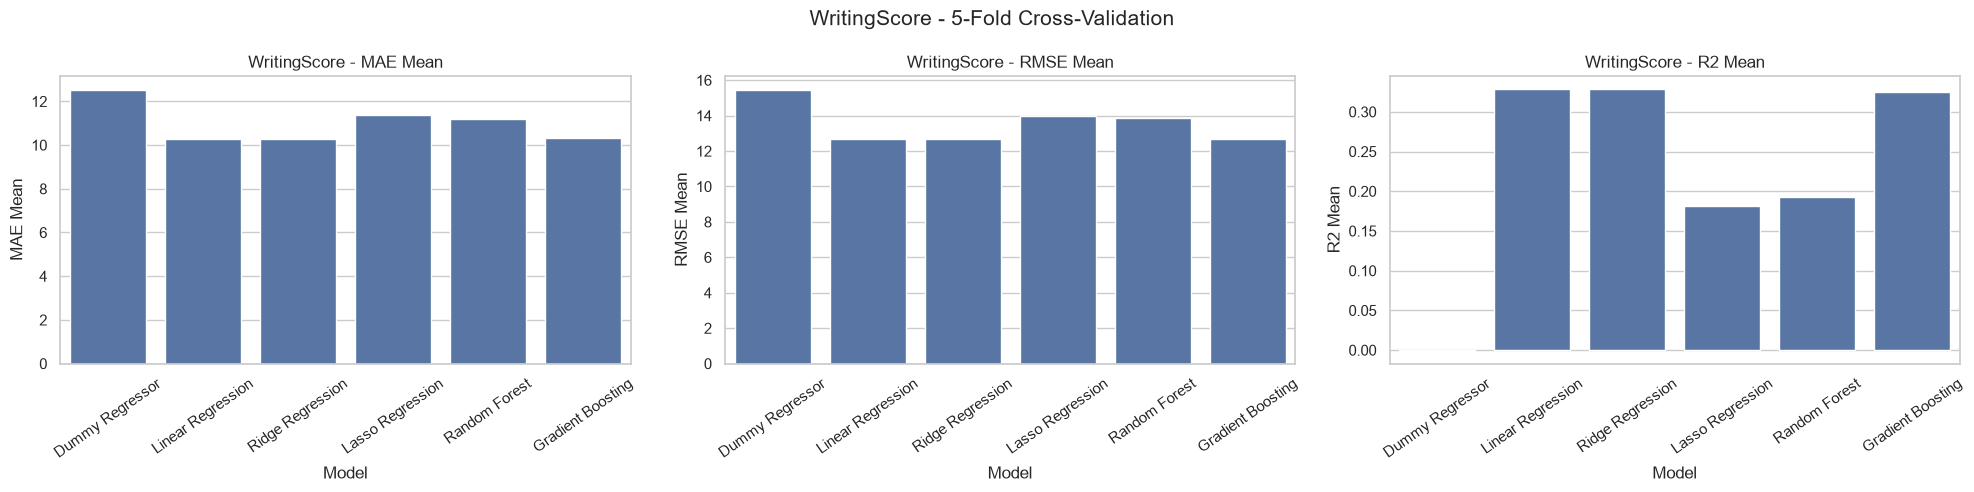

In [35]:
for target_name in targets:
    target_results = cv_results[cv_results["Target"] == target_name]

    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    metric_columns = [
        ("MAE Mean", "MAE Mean"),
        ("RMSE Mean", "RMSE Mean"),
        ("R2 Mean", "R2 Mean")
    ]

    for ax, (metric, label) in zip(axes, metric_columns):
        sns.barplot(data=target_results, x="Model", y=metric, ax=ax)
        ax.set_title(f"{target_name} - {label}")
        ax.set_xlabel("Model")
        ax.set_ylabel(label)
        ax.tick_params(axis="x", rotation=35)

    plt.suptitle(f"{target_name} - 5-Fold Cross-Validation", fontsize=15)
    plt.tight_layout()
    plt.show()

## 11. Final Comparison and Ranking

The tables below rank the six fixed model configurations by test-set MAE and cross-validation MAE. Lower MAE indicates a smaller average absolute prediction error.

Use the complete metric tables above as well: model selection should consider MAE, RMSE, R², and cross-validation variability rather than relying on a single metric alone.

In [36]:
for target_name in targets:
    print(f"\n{target_name} - Test Set Ranking by MAE")
    display(
        test_results[test_results["Target"] == target_name]
        .sort_values("MAE")
        .reset_index(drop=True)
        .round(4)
    )

    print(f"{target_name} - Cross-Validation Ranking by MAE")
    display(
        cv_results[cv_results["Target"] == target_name]
        .sort_values("MAE Mean")
        .reset_index(drop=True)
        .round(4)
    )


MathScore - Test Set Ranking by MAE


,Target,Model,MAE,RMSE,R2 Score
0,MathScore,Linear Regression,10.3745,12.8284,0.2907
1,MathScore,Ridge Regression,10.3745,12.8284,0.2908
2,MathScore,Gradient Boosting,10.4018,12.8680,0.2864
3,MathScore,Random Forest,11.3358,14.0686,0.1470
4,MathScore,Lasso Regression,11.3891,14.0999,0.1432
5,MathScore,Dummy Regressor,12.3182,15.2372,-0.0006


MathScore - Cross-Validation Ranking by MAE


,Target,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,MathScore,Linear Regression,10.4942,0.1133,12.9710,0.1449,0.2896,0.0115
1,MathScore,Ridge Regression,10.4942,0.1133,12.9711,0.1449,0.2896,0.0115
2,MathScore,Gradient Boosting,10.5296,0.1140,13.0101,0.1440,0.2854,0.0110
3,MathScore,Random Forest,11.4180,0.1173,14.1589,0.1577,0.1536,0.0134
4,MathScore,Lasso Regression,11.5680,0.1067,14.2819,0.1450,0.1389,0.0018
5,MathScore,Dummy Regressor,12.4506,0.1199,15.3923,0.1550,-0.0002,0.0003



ReadingScore - Test Set Ranking by MAE


,Target,Model,MAE,RMSE,R2 Score
0,ReadingScore,Linear Regression,10.3961,12.8326,0.2346
1,ReadingScore,Ridge Regression,10.3961,12.8326,0.2346
2,ReadingScore,Gradient Boosting,10.4128,12.8545,0.2320
3,ReadingScore,Lasso Regression,11.2418,13.8549,0.1078
4,ReadingScore,Random Forest,11.3199,14.0161,0.0869
5,ReadingScore,Dummy Regressor,11.8693,14.6701,-0.0003


... (2 outputs left out)


WritingScore - Test Set Ranking by MAE


,Target,Model,MAE,RMSE,R2 Score
0,WritingScore,Linear Regression,10.1420,12.5203,0.3363
1,WritingScore,Ridge Regression,10.1420,12.5204,0.3363
2,WritingScore,Gradient Boosting,10.1648,12.5389,0.3343
3,WritingScore,Random Forest,11.1628,13.8159,0.1919
4,WritingScore,Lasso Regression,11.1752,13.8310,0.1901
5,WritingScore,Dummy Regressor,12.4239,15.3725,-0.0005


WritingScore - Cross-Validation Ranking by MAE


,Target,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,WritingScore,Linear Regression,10.2780,0.0526,12.6664,0.0542,0.3286,0.0041
1,WritingScore,Ridge Regression,10.2780,0.0526,12.6664,0.0542,0.3286,0.0041
2,WritingScore,Gradient Boosting,10.3179,0.0504,12.7035,0.0552,0.3247,0.0047
3,WritingScore,Random Forest,11.2094,0.0108,13.8886,0.0475,0.1928,0.0048
4,WritingScore,Lasso Regression,11.3543,0.0480,13.9848,0.0548,0.1816,0.0035
5,WritingScore,Dummy Regressor,12.5320,0.0555,15.4625,0.0528,-0.0005,0.0004


## 12. Conclusion

Complete the project conclusion after running all cells. Report the model that performs best for each target based on the observed results, and mention whether the test-set and cross-validation comparisons tell a similar story.

### Points to discuss
1. Which model has the lowest MAE for MathScore, ReadingScore, and WritingScore?
2. Do the RMSE and R² results support the same model choice?
3. Are the cross-validation mean scores close to the test-set results?
4. Which model has the most consistent cross-validation results (smaller standard deviation)?
5. What does the Dummy Regressor baseline tell us about the value added by the other models?

**Scope note:** this project ends with model comparison and interpretation. It does not perform Grid Search, Randomized Search, hyperparameter tuning, or further model optimization.